In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [47]:
df = pd.read_csv("../../course_assignments/homework9/solar_system.csv", index_col=0)

print(df.shape)  # Will now be (20, 10): 20 measurements, 10 celestial bodies
print(df.head(5))


(20, 10)
                       Mercury  Venus  Earth   Moon   Mars Jupiter  Saturn  \
Attribute                                                                    
Mass (10^24kg)           0.330   4.87   5.97  0.073  0.642    1898     568   
Diameter (km)             4879  12104  12756   3475   6792  142984  120536   
Density (kg/m^3)          5429   5243   5514   3340   3934    1326     687   
Gravity (m/s^2)            3.7    8.9    9.8    1.6    3.7    23.1     9.0   
Escape Velocity (km/s)     4.3   10.4   11.2    2.4    5.0    59.5    35.5   

                       Uranus Neptune   Pluto  
Attribute                                      
Mass (10^24kg)           86.8     102  0.0130  
Diameter (km)           51118   49528    2376  
Density (kg/m^3)         1270    1638    1850  
Gravity (m/s^2)           8.7    11.0     0.7  
Escape Velocity (km/s)   21.3    23.5     1.3  


In [48]:
print(df.tail(5))

                        Mercury Venus Earth Moon  Mars  Jupiter   Saturn  \
Attribute                                                                  
Mean Temperature (C)        167   464    15  -20   -65     -110     -140   
Surface Pressure (bars)       0    92     1    0  0.01  Unknown  Unknown   
Number of Moons               0     0     1    0     2       95      274   
Ring System?                 No    No    No   No    No      Yes      Yes   
Global Magnetic Field?      Yes    No   Yes   No    No      Yes      Yes   

                          Uranus  Neptune    Pluto  
Attribute                                           
Mean Temperature (C)        -195     -200     -225  
Surface Pressure (bars)  Unknown  Unknown  0.00001  
Number of Moons               28       16        5  
Ring System?                 Yes      Yes       No  
Global Magnetic Field?       Yes      Yes  Unknown  


In [49]:
print()
print(df.columns)
print(df.index)


Index(['Mercury', 'Venus', 'Earth', 'Moon', 'Mars', 'Jupiter', 'Saturn',
       'Uranus', 'Neptune', 'Pluto'],
      dtype='str')
Index(['Mass (10^24kg)', 'Diameter (km)', 'Density (kg/m^3)',
       'Gravity (m/s^2)', 'Escape Velocity (km/s)', 'Rotation Period (hours)',
       'Length of Day (hours)', 'Distance from Sun (10^6 km)',
       'Perihelion (10^6 km)', 'Aphelion (10^6 km)', 'Orbital Period (days)',
       'Orbital Velocity (km/s)', 'Orbital Inclination (deg)',
       'Orbital Eccentricity', 'Obliquity to Orbit (deg)',
       'Mean Temperature (C)', 'Surface Pressure (bars)', 'Number of Moons',
       'Ring System?', 'Global Magnetic Field?'],
      dtype='str', name='Attribute')


(21, 10)
Fit: T = 0.20 * a^1.5


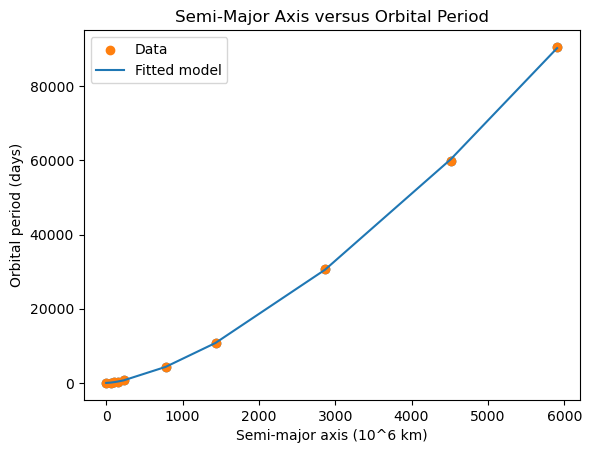

In [50]:
perihelion = df.iloc[8].astype(float)
aphelion = df.iloc[9].astype(float)
orbital_period = df.iloc[10].astype(float)


semi_major_axis = pd.Series((perihelion + aphelion) / 2, name = "semi_major_axis")

df = pd.concat([df, semi_major_axis.to_frame().T], axis=0)
print(df.shape)
# 22 rows, 10 columns

plt.scatter(x=semi_major_axis, y=orbital_period)
plt.title("Semi-Major Axis versus Orbital Period")
plt.xlabel("Semi-major axis (10^6 km)")
plt.ylabel("Orbital period (days)")

def keplers_third_law(a, m):
    return m * a ** 1.5

popt, pcov = curve_fit(keplers_third_law, semi_major_axis, orbital_period)

m_fit = popt[0]
print(f"Fit: T = {m_fit:.2f} * a^1.5")

residuals = orbital_period - keplers_third_law(semi_major_axis, m_fit)
chi2 = np.sum(residuals**2)
dof = len(semi_major_axis) - len(popt)
chi2_reduced = chi2 / dof

a_sorted = np.sort(semi_major_axis)
plt.scatter(semi_major_axis, orbital_period, label="Data")
plt.plot(a_sorted, keplers_third_law(a_sorted, m_fit), label="Fitted model")
plt.legend()
plt.show()

df.to_csv("kepler.csv")